In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("penguins.csv")
df.head(10)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,female,2007
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,male,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007


#  EDA

In [4]:
df.shape

(344, 8)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 27.6 KB


In [6]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


In [7]:
df.isnull().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

In [8]:
df.columns

Index(['species', 'island', 'bill_length_mm', 'bill_depth_mm',
       'flipper_length_mm', 'body_mass_g', 'sex', 'year'],
      dtype='str')

In [9]:
df['bill_length_mm'] = df['bill_length_mm'].fillna(df['bill_length_mm'].median())

df['bill_depth_mm'] = df['bill_depth_mm'].fillna(df['bill_depth_mm'].median())

df['flipper_length_mm'] = df['flipper_length_mm'].fillna(df['flipper_length_mm'].median())

df['body_mass_g'] = df['body_mass_g'].fillna(df['body_mass_g'].median())

In [10]:
print(df.columns.tolist())

['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']


In [11]:
df['sex'] = df['sex'].fillna(df['sex'].mode()[0])

In [12]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     344 non-null    float64
 3   bill_depth_mm      344 non-null    float64
 4   flipper_length_mm  344 non-null    float64
 5   body_mass_g        344 non-null    float64
 6   sex                344 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 27.6 KB


In [13]:
# df['sex'].fillna('Unknown', inplace=True)

In [14]:
df.isnull().sum()

species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
year                 0
dtype: int64

In [15]:
df['species'].unique()

<ArrowStringArray>
['Adelie', 'Gentoo', 'Chinstrap']
Length: 3, dtype: str

In [16]:
df['species'].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

<Axes: xlabel='species'>

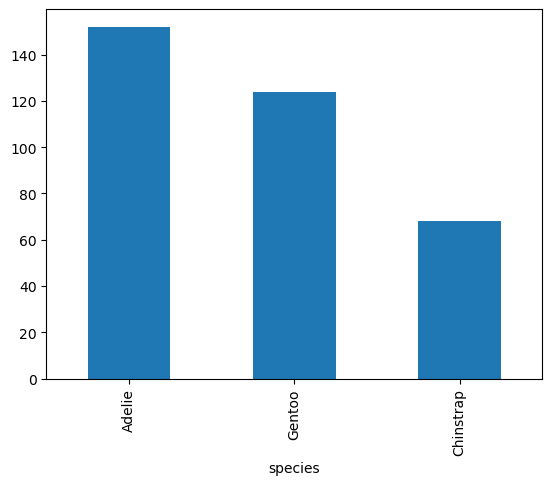

In [17]:
df['species'].value_counts().plot(kind = 'bar')

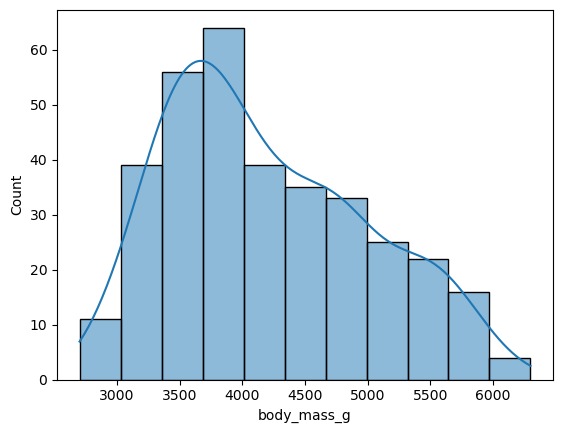

In [18]:
sns.histplot(data = df,x = "body_mass_g", kde = True )
plt.show()

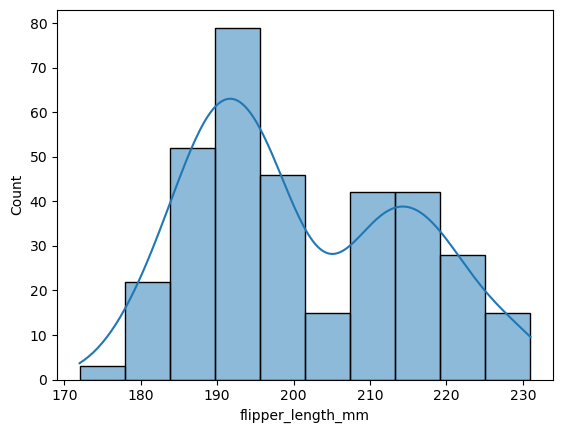

In [19]:
sns.histplot(data = df,x = "flipper_length_mm", kde = True )
plt.show()

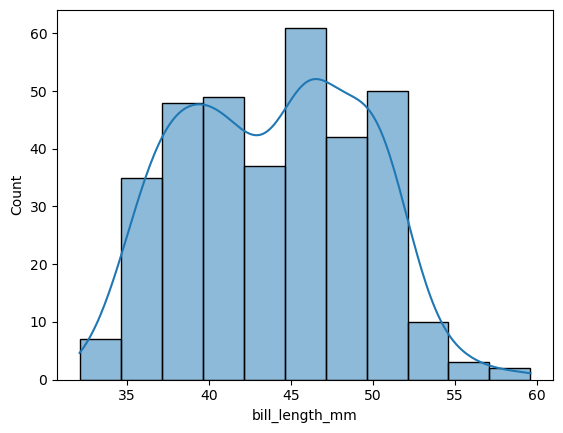

In [20]:
sns.histplot(data = df,x = "bill_length_mm", kde = True )
plt.show()

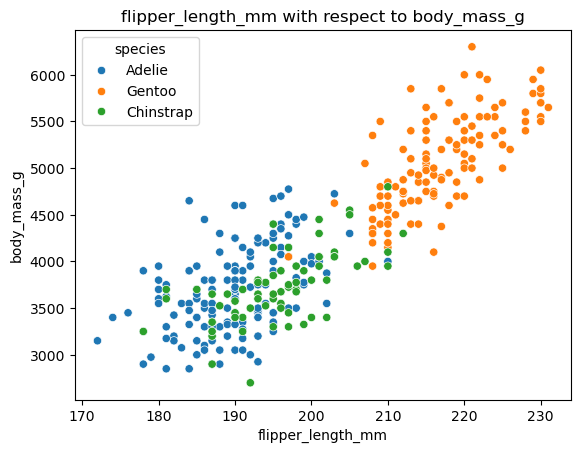

In [21]:
sns.scatterplot(data=df,
    x='flipper_length_mm',
    y='body_mass_g',
    hue='species')
plt.title("flipper_length_mm with respect to body_mass_g")
plt.show()

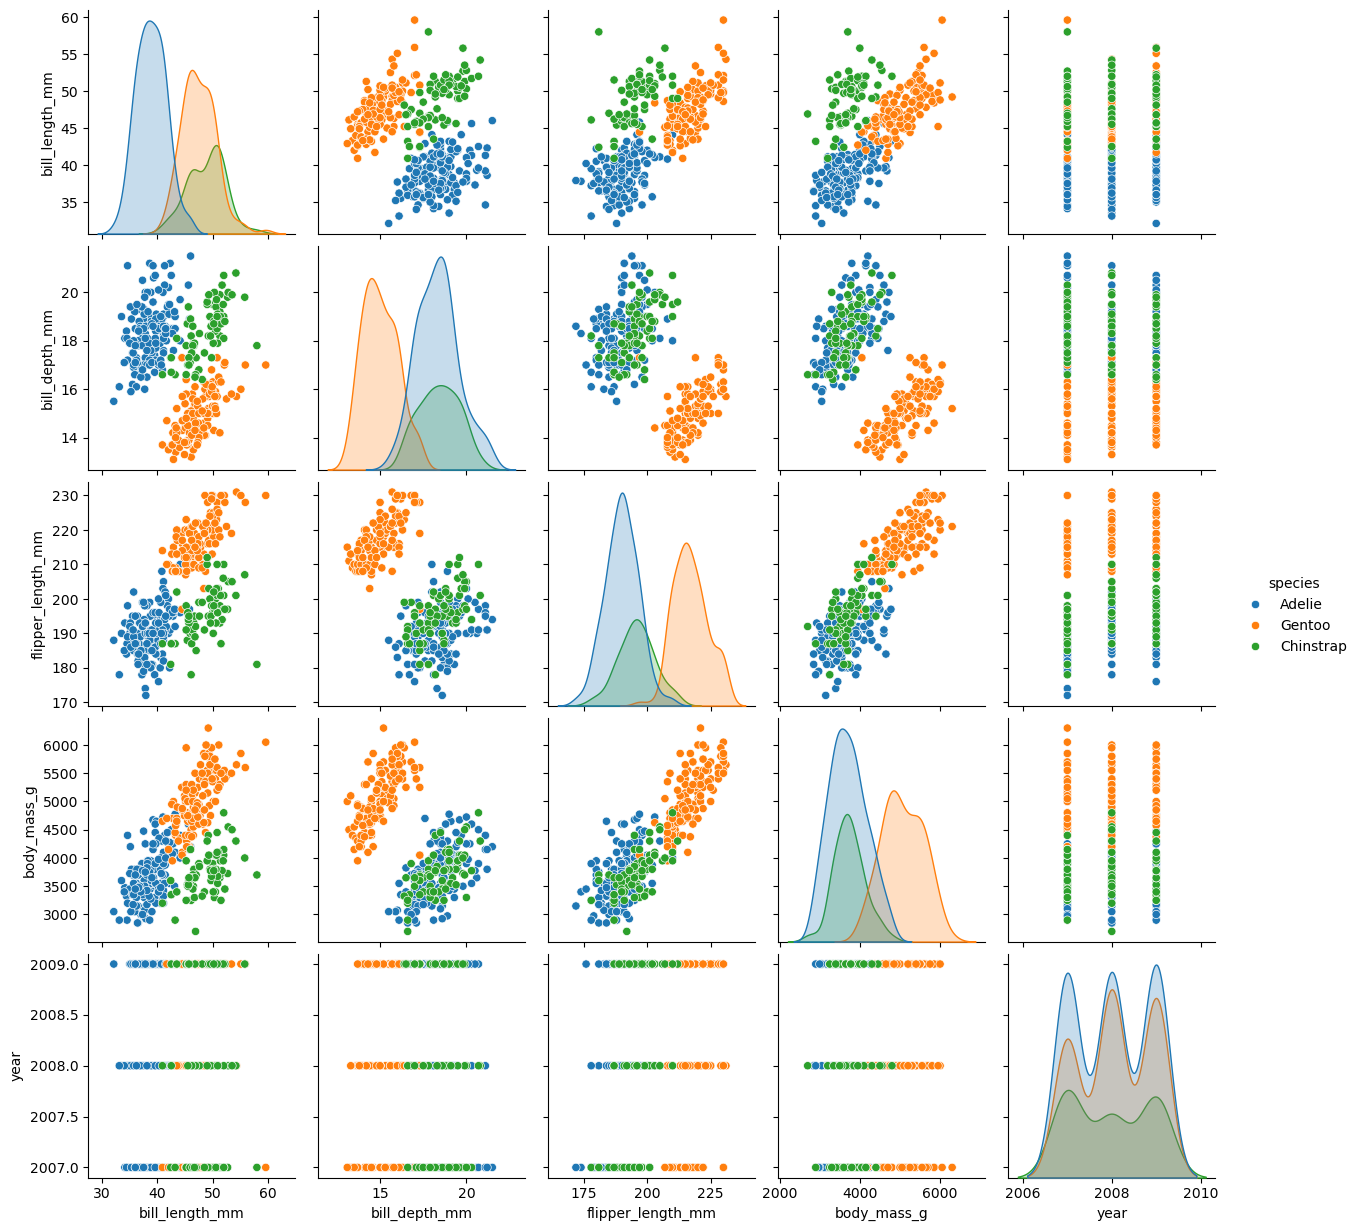

In [22]:
sns.pairplot(df, hue='species')
plt.show()

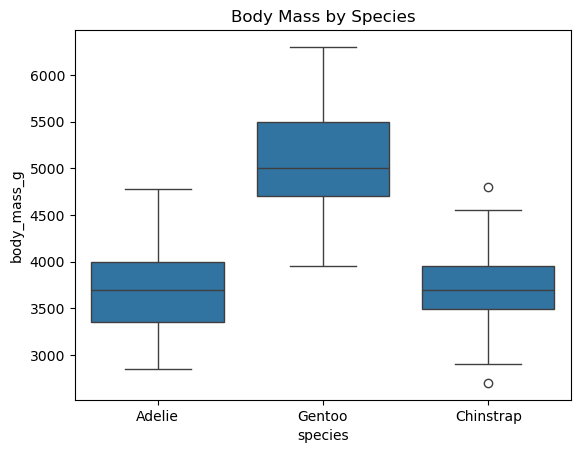

In [23]:
sns.boxplot(data=df, x='species', y='body_mass_g')
plt.title('Body Mass by Species')
plt.show()

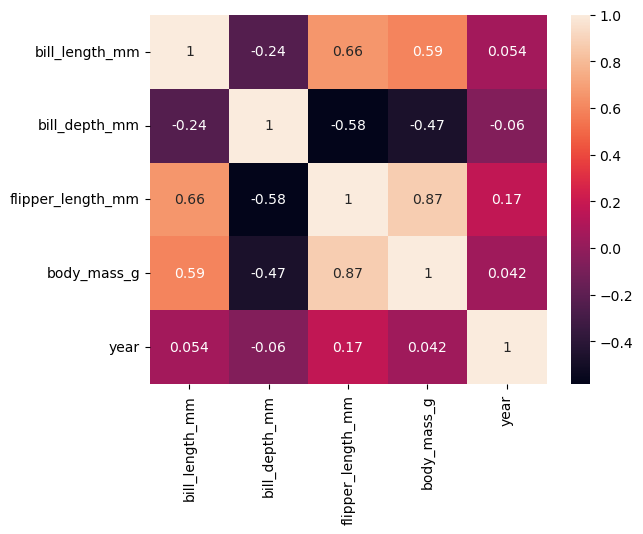

In [24]:
sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
  
)
plt.show()

#  Model Train

In [25]:
df = pd.get_dummies(df, columns=['island', 'sex'], dtype=int)

In [26]:
df.head(10)

,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year,island_Biscoe,island_Dream,island_Torgersen,sex_female,sex_male
0,Adelie,39.10,18.7,181.0,3750.0,2007,0,0,1,0,1
1,Adelie,39.50,17.4,186.0,3800.0,2007,0,0,1,1,0
2,Adelie,40.30,18.0,195.0,3250.0,2007,0,0,1,1,0
3,Adelie,44.45,17.3,197.0,4050.0,2007,0,0,1,0,1
4,Adelie,36.70,19.3,193.0,3450.0,2007,0,0,1,1,0
5,Adelie,39.30,20.6,190.0,3650.0,2007,0,0,1,0,1
6,Adelie,38.90,17.8,181.0,3625.0,2007,0,0,1,1,0
7,Adelie,39.20,19.6,195.0,4675.0,2007,0,0,1,0,1
8,Adelie,34.10,18.1,193.0,3475.0,2007,0,0,1,0,1
9,Adelie,42.00,20.2,190.0,4250.0,2007,0,0,1,0,1


In [27]:
print(df.columns)

Index(['species', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm',
       'body_mass_g', 'year', 'island_Biscoe', 'island_Dream',
       'island_Torgersen', 'sex_female', 'sex_male'],
      dtype='str')


#  Seperate X and y

In [28]:
X = df[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm',
       'body_mass_g', 'year', 'island_Biscoe', 'island_Dream',
       'island_Torgersen', 'sex_female', 'sex_male']]
y = df['species']

#  Split into training and testing data

In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,y, test_size = 0.2, random_state= 50)

In [30]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (275, 10)
Testing data: (69, 10)


#  Feature Scaling

In [31]:
from sklearn.preprocessing  import StandardScaler

scaler= StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#  Import KNN

In [32]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors = 5)

#  Train the Model

In [33]:
knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['Adelie','Chinstrap','Gentoo']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


#  Make Prediction

In [34]:
y_pred = knn.predict(X_test_scaled)
y_pred[:15]

array(['Chinstrap', 'Gentoo', 'Gentoo', 'Adelie', 'Adelie', 'Chinstrap',
       'Adelie', 'Adelie', 'Adelie', 'Chinstrap', 'Adelie', 'Gentoo',
       'Gentoo', 'Adelie', 'Gentoo'], dtype=object)

#  Compare Actual and Predicted

In [35]:
comparison = pd.DataFrame({
"Actual" : y_test.values,
"Predicted" : y_pred
})

comparison.head(20)

,Actual,Predicted
0,Chinstrap,Chinstrap
1,Gentoo,Gentoo
2,Gentoo,Gentoo
3,Adelie,Adelie
4,Adelie,Adelie
5,Chinstrap,Chinstrap
6,Adelie,Adelie
7,Adelie,Adelie
8,Adelie,Adelie
9,Chinstrap,Chinstrap


#  Calculate Accuracy

In [36]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy*100,'%')


Accuracy: 0.9855072463768116
Accuracy Percentage: 98.55072463768117 %


#  Confusion Matrix

In [37]:
from sklearn.metrics import confusion_matrix
cm =confusion_matrix(y_test, y_pred)
print(cm)

[[34  0  0]
 [ 0 12  0]
 [ 1  0 22]]


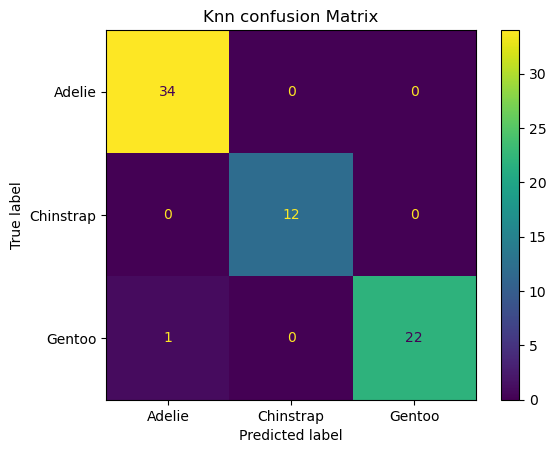

In [38]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

plt.title("Knn confusion Matrix")
plt.show()

#  Classification Report

In [39]:
from sklearn.metrics import classification_report

print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

      Adelie       0.97      1.00      0.99        34
   Chinstrap       1.00      1.00      1.00        12
      Gentoo       1.00      0.96      0.98        23

    accuracy                           0.99        69
   macro avg       0.99      0.99      0.99        69
weighted avg       0.99      0.99      0.99        69



#  Testing different K values

In [40]:
k_values = range(1,21)

accuracies = []

for k in k_values:

    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)
    accuracies.append(accuracy)

In [41]:
best_k = k_values[np.argmax(accuracies)]
best_accuracy = max(accuracies)

print("best K:",best_k)
print("Best Accuracy:", best_accuracy)

best K: 1
Best Accuracy: 0.9855072463768116


#  Visualize K vs Accuracy

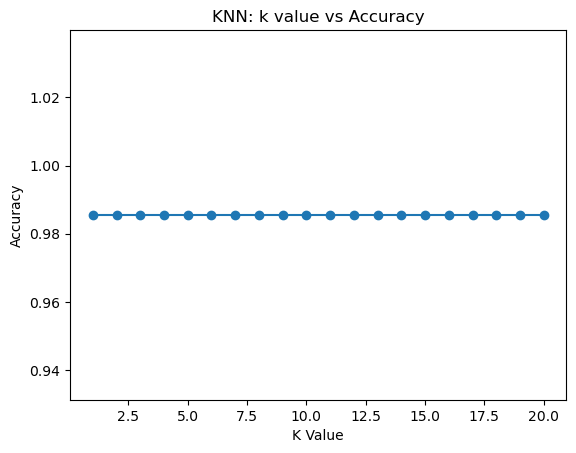

In [42]:
plt.plot(k_values, accuracies, marker = "o")

plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("KNN: k value vs Accuracy")

plt.show()

#   Train final model with best K

In [43]:
best_knn = KNeighborsClassifier(n_neighbors=  best_k)

best_knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['Adelie','Chinstrap','Gentoo']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [44]:
final_predictions = best_knn.predict(X_test_scaled)

final_accuracy = accuracy_score(y_test, final_predictions)

print("Final Accurqacy:", final_accuracy)

Final Accurqacy: 0.9855072463768116


#  New data prediction

In [45]:
new_penguin_data = pd.DataFrame({
    'bill_length_mm': [44],
    'bill_depth_mm': [17],
    'flipper_length_mm': [200],
    'body_mass_g': [4500],
    'year': [2009],
    'island_Biscoe': [1],
    'island_Dream': [0],
    'island_Torgersen': [0],
    'sex_female': [1],
    'sex_male': [0]
})

new_penguin_data

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year,island_Biscoe,island_Dream,island_Torgersen,sex_female,sex_male
0,44,17,200,4500,2009,1,0,0,1,0


In [46]:
new_penguin_data_scaled = scaler.transform(new_penguin_data)

In [48]:
#  Predict

prediction = best_knn.predict(new_penguin_data_scaled)
print("Prediction Result:", prediction[0])

Prediction Result: Gentoo


#  Model Deployment

In [52]:
import joblib

joblib.dump(best_knn, 'knn_model.pkl')
joblib.dump(scaler, 'scaler.pkl')


['scaler.pkl']

#  Prediction Function

In [56]:
def predict_result(bill_length_mm, bill_depth_mm, flipper_length_mm,
       body_mass_g, year, island_Biscoe, island_Dream,
       island_Torgersen, sex_female, sex_male):
    
    new_penguin_data =[(bill_length_mm, bill_depth_mm, flipper_length_mm,
       body_mass_g, year, island_Biscoe, island_Dream,
       island_Torgersen, sex_female, sex_male)]
    
    new_penguin_data_scaled = scaler.transform(new_penguin_data)\

    prediction = best_knn.predict(new_penguin_data_scaled)

    return prediction[0]


    

In [ ]:
result = predict_result(
    45.2,
    17.5,
    200,
    4500,
    2008,
    1,
    0,
    0,
    1,
    0
)

print(result)

Gentoo


C:\Users\Lenovo\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
